## Praktikum 2
##### Erweiterte Operationen auf Gesichtern

In diesem Praktikum betrachten wir weitere Operationen auf Gesichtern und trainieren erste kleine Netzwerke zur Gesichtserkennung.

<div style="padding: 10px; border-left: 5px solid #B777FA; background-color: #5C18FA; border-radius: 4px">
  🐍 Bitte nutzen Sie die virtuelle Umgebung: <b>DLACV_2526</b>
</div>

In [76]:
# imports
import cv2
import dlib
import numpy as np
import utils.faceBlendCommon as fbc
import matplotlib.pyplot as plt
import matplotlib
from utils.dataPath import DATA_PATH
%matplotlib inline

In [77]:
# matplotlib-Einstellungen
matplotlib.rcParams['figure.figsize'] = (8.0,8.0)
matplotlib.rcParams['image.cmap'] = 'gray'
matplotlib.rcParams['image.interpolation'] = 'bilinear'

# Resize-Optionen
FACE_DOWNSAMPLE_RATIO = 1
RESIZE_HEIGHT = 320

# Gesichts- und Landmarkendetektor initialisieren
modelPath = DATA_PATH + "models/shape_predictor_68_face_landmarks.dat"
detector = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor(modelPath)

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.1:</b><br>
  • Lesen Sie die Bilder <code>data/images/ted_cruz.jpg</code> und <code>data/images/beard.png</code> ein und geben diese im Notebook aus.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Überprüfen Sie das Format und die Kanäle, in denen das Bild eingelesen wird.<br>Sollte das Bild nicht richtig aussehen, ist möglicherweise die Reihenfolge der Farbkanäle falsch.
</div>

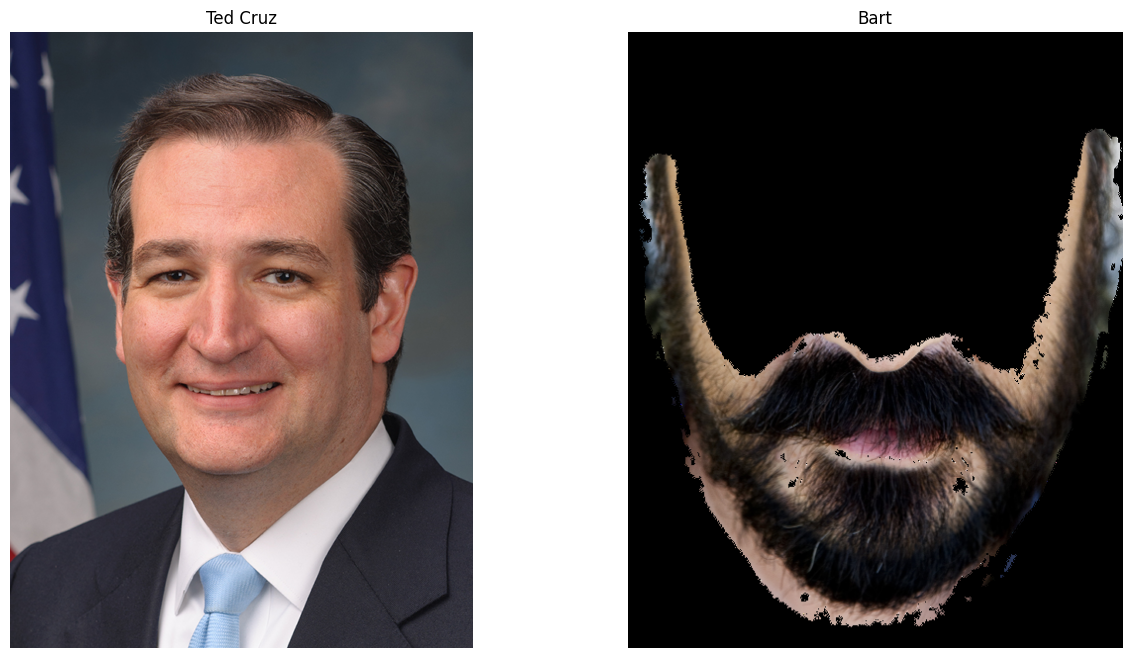

In [78]:
# Bilder einlesen und in RGB konvertieren
ted = cv2.imread("data/images/ted_cruz.jpg")
beard = cv2.imread("data/images/beard.png")
ted = cv2.cvtColor(ted, cv2.COLOR_RGB2BGR)
beard = cv2.cvtColor(beard, cv2.COLOR_RGB2BGR)

# Anzeigen
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

axes[0].imshow(ted)
axes[0].axis('off')
axes[0].set_title('Ted Cruz')

axes[1].imshow(beard)
axes[1].axis('off')
axes[1].set_title('Bart')

plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.2:</b><br>
  Um den Bart auf die richtigen Teile des Gesichtes abzubilden, werden korrespondierende Punkte gebraucht.<br>
  • Notieren Sie die in der folgenden Abbildung rechts (Ted Cruz) blau markierten Punkte in der Reihenfolge, sodass sie mit der Reihenfolge des linken Bildes (Bart) korrekt korrespondieren.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis 1:</b></i> Beachten Sie im rechten Bild (Ted Cruz) nur die blau eingefärbten Punkte.<br>
💡 <i><b>Hinweis 2:</b></i> Das Ziel-Array beinhaltet die Indizes des rechten Bildes (Ted Cruz) in der Reihenfolge im linken Bild (Bart).
</div>

<center>
<img src="data/images/ted-beardify-annotation.jpg" width=1000>
</center>

In [79]:
# Korrespondierende Punkte
selectedIndex = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,31,32,33,34,35,55,56,57,58,59]

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.3:</b><br>
  • Lesen Sie erneut <code>data/images/beard.png</code> ein. Lesen Sie diesmal zusätzlich den Alpha-Kanal des Bildes mit ein.<br>
  • Spalten Sie die Kanäle des Bildes auf und erzeugen, wie in Aufgabe 1.5, ein Farbkanalbild und eine Alpha-Maske.<br>
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis 1:</b></i> Überprüfen Sie das Format und die Kanäle, in denen das Bild eingelesen wird.<br>Sollte das Bild nicht richtig aussehen, ist möglicherweise die Reihenfolge der Farbkanäle falsch.<br>
💡 <i><b>Hinweis 2:</b></i> Nutzen Sie zum Aufbrechen und Zusammenfügen der Kanäle jeweils eine einzige <code>cv2</code>-Funktion.<br>
💡 <i><b>Hinweis 3:</b></i> Es kann für spätere Funktionen notwendig sein, das Farbkanalbild zu normalisieren.
</div>

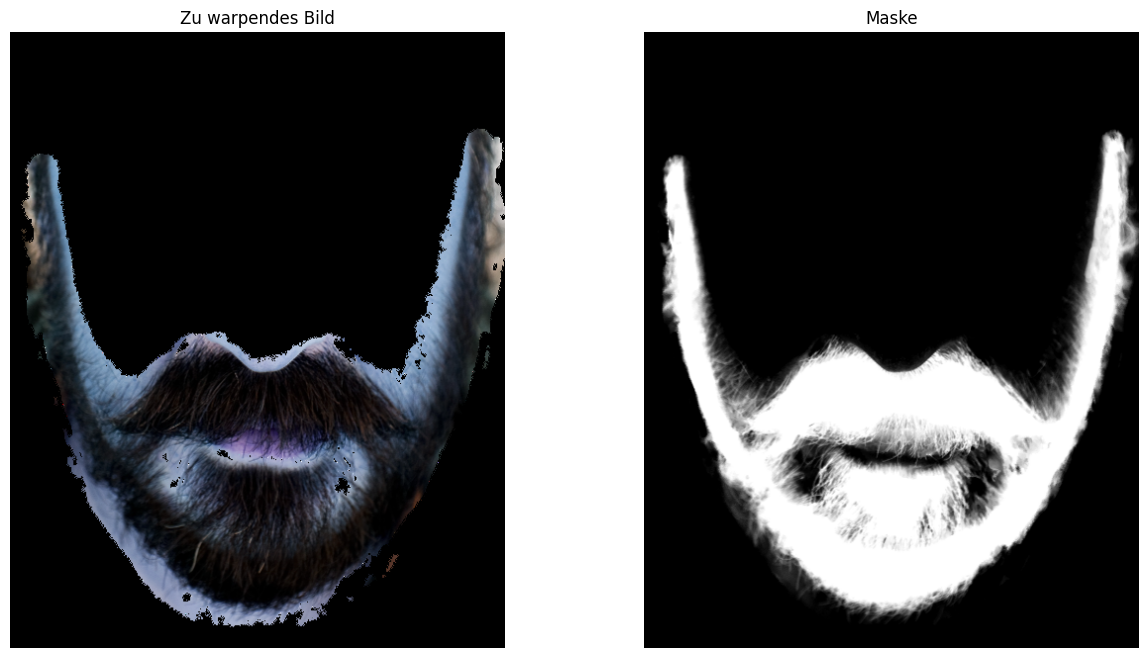

In [80]:
beard = cv2.imread("data/images/beard.png", -1)
r,g,b,a = cv2.split(beard)
beard_rgb = cv2.merge((r,g,b))
beard_alpha = cv2.merge((a,a,a))

# Anzeigen
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

axes[0].imshow(beard_rgb)
axes[0].axis('off')
axes[0].set_title('Zu warpendes Bild')

axes[1].imshow(beard_alpha)
axes[1].axis('off')
axes[1].set_title('Maske')

plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.4:</b><br>
  • Führen Sie eine Delauney-Triangulation mit der entsprechenden <code>fbc</code>-Funktion durch.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Nutzen Sie <code>beard.shape</code>, um die Größe eines der benötigten Parameter zu berechnen.
</div>

In [81]:
# Laden der Pixelkoordinaten der Bart-Punkte aus der Textdatei
def getSavedPoints(beardPointsFile):
  points = []
  lines = np.loadtxt(beardPointsFile, dtype='uint16')
  
  for p in lines:
    points.append((p[0], p[1]))
  
  return points 

# Punkte des Bartes auslesen
featurePoints1 = getSavedPoints(DATA_PATH + "images/landmarks/beard.png.txt")
# Delauney-Triangulation für konvexe Hull-Punkte berechnen
dt = fbc.calculateDelaunayTriangles((0,0,beard.shape[1],beard.shape[0]),featurePoints1)

if len(dt) == 0:
    print("Keine Delauney-Dreiecke gefunden.")

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.5:</b><br>
  • Vervollständigen Sie den Beardify-Filter, indem Sie eine affine Transformation auf die Delauney-Dreiecke anwenden und ein abschließendes Alpha-Blending durchführen.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis 1:</b></i> Achten Sie darauf, ob Sie nach dem Warpen normalisieren müssen.<br>
💡 <i><b>Hinweis 2:</b></i> Sie benötigen unter Umständen weitere Funktionen aus <code>fbc</code>.
</div>

(320, 240, 3)


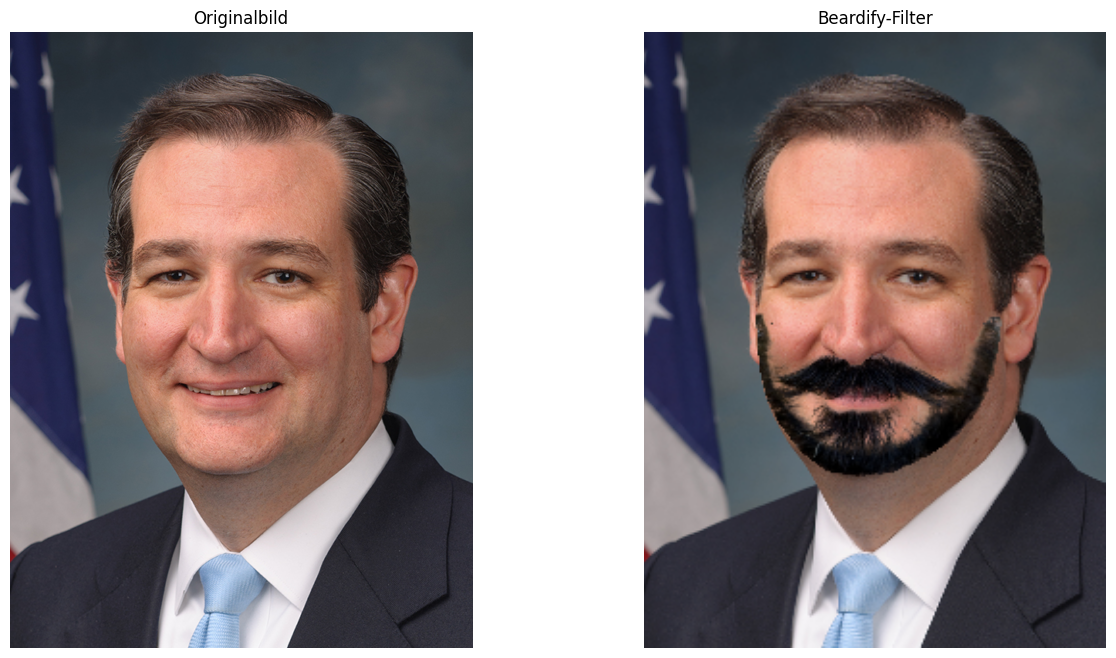

In [91]:
# Bild einlesen
imageFile = DATA_PATH + "images/ted_cruz.jpg"
targetImage = cv2.imread(imageFile)

# Dimensionen bestimmen
height, width = targetImage.shape[:2]

# Resize-Faktor (für Zielbild) bestimmen
IMAGE_RESIZE = np.float32(height) / RESIZE_HEIGHT

# Zielbild anlegen
targetImage = cv2.resize(targetImage,None,
                 fx=1.0/IMAGE_RESIZE,
                 fy=1.0/IMAGE_RESIZE,
                 interpolation = cv2.INTER_LINEAR)

# Landmarken bestimmen
points2 = fbc.getLandmarks(detector, predictor, cv2.cvtColor(targetImage, cv2.COLOR_BGR2RGB), FACE_DOWNSAMPLE_RATIO)
featurePoints2 = []
for p in selectedIndex:
    pt = points2[p]
    pt = fbc.constrainPoint(pt, width, height)
    featurePoints2.append(pt)

# Bild normalisieren
targetImage = np.float32(targetImage)/255

# Gewarpte Zielbilder anlegen
beardWarped = np.zeros(targetImage.shape,dtype=targetImage.dtype)
beardAlphaWarped = np.zeros(targetImage.shape,dtype=targetImage.dtype)

# Affine Transformation auf Delauney-Dreiecke anwenden
for i in range(0, len(dt)):
    t1 = [featurePoints1[dt[i][0]],featurePoints1[dt[i][1]],featurePoints1[dt[i][2]]]
    t2 = [featurePoints2[dt[i][0]],featurePoints2[dt[i][1]],featurePoints2[dt[i][2]]]
    fbc.warpTriangle(beard_rgb,beardWarped,t1,t2)
    fbc.warpTriangle(beard_alpha,beardAlphaWarped,t1,t2)


# Maske normalisieren und Alpha-Blending durchführen
beardWarped = cv2.cvtColor(beardWarped,cv2.COLOR_RGB2BGR)
beardWarped = np.float32(beardWarped)/255
targetImage = fbc.alphaBlend(beardAlphaWarped,beardWarped,targetImage)
print(targetImage.shape)
cv2.cvtColor(targetImage,cv2.COLOR_RGB2BGR,targetImage)
# Anzeigen
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

axes[0].imshow(ted)
axes[0].axis('off')
axes[0].set_title('Originalbild')

axes[1].imshow(targetImage)
axes[1].axis('off')
axes[1].set_title('Beardify-Filter')

plt.show()